# 00 · Thermodynamic reference and the synthetic world

This notebook fixes the label mathematics before any data are touched: units, saturation-pressure formula, the dew-point inverse, how instrument error propagates into the dew-point depression `D = T − Td`, and an instrument-derived censoring rule. It then defines the linear-Gaussian synthetic world whose conditional mutual information is known exactly, which notebook 01 uses to validate the information estimator.

Nothing here is weather evidence. Instrument numbers (±2 %RH, ±0.2 K) are illustrative specifications, to be replaced by the actual instrument datasheets of each source.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from visual_hygrometry import thermo, synthetic
from visual_hygrometry.synthetic import Node

plt.rcParams.update({'figure.dpi': 80, 'figure.figsize': (8, 3.2), 'axes.grid': True, 'grid.alpha': .3})
pd.set_option('display.precision', 4)

## 1 · Saturation vapour pressure

Labels use the Magnus form `e_s(T) = 6.112 exp(17.62 T / (243.12 + T))` hPa over liquid water (WMO-No. 8 coefficients), because its dew-point inverse is closed-form and exact. Accuracy is checked against IAPWS-95 steam-table values and against the Murphy & Koop (2005) liquid-water formula, which itself reproduces the tables to < 0.01 %.

In [2]:
steam = pd.Series({0.01: 6.11657, 10: 12.282, 20: 23.393, 25: 31.699, 30: 42.470, 40: 73.849, 50: 123.52})
t = steam.index.to_numpy()
pd.DataFrame({'steam_hpa': steam.values, 'mk_err_pct': 100 * (thermo.es_mk(t) / steam.values - 1),
              'magnus_err_pct': 100 * (thermo.es_magnus(t) / steam.values - 1)}, index=pd.Index(t, name='temp_c'))

,steam_hpa,mk_err_pct,magnus_err_pct
temp_c,,,
0.01,6.1166,7.1354e-06,-0.0023
10.00,12.2820,4.6773e-03,-0.1767
20.00,23.3930,4.2330e-03,-0.2866
25.00,31.6990,1.1580e-03,-0.3105
30.00,42.4700,-4.3778e-03,-0.3126
40.00,73.8490,-8.0392e-03,-0.2362
50.00,123.5200,-1.3766e-04,-0.0554


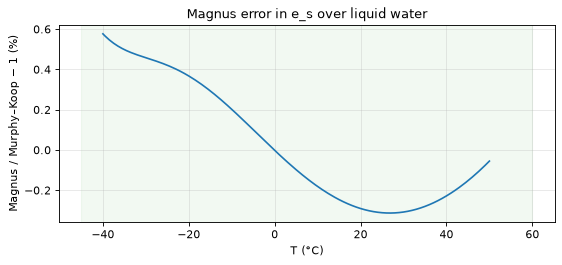

max |error| on -40..50 °C: 0.577 %, at -40 °C


In [3]:
tc = np.linspace(-40, 50, 181)
rel = 100 * (thermo.es_magnus(tc) / thermo.es_mk(tc) - 1)
plt.plot(tc, rel)
plt.axvspan(-45, 60, color='C2', alpha=.06)
plt.xlabel('T (°C)'); plt.ylabel('Magnus / Murphy–Koop − 1 (%)'); plt.title('Magnus error in e_s over liquid water')
plt.show()
print(f'max |error| on -40..50 °C: {np.abs(rel).max():.3f} %, at {tc[np.argmax(np.abs(rel))]:.0f} °C')

## 2 · What the formula choice does to D

`D` depends on a ratio of saturation pressures, `RH = 100 e_s(T−D)/e_s(T)`, so a slowly varying relative error in `e_s` largely cancels. We compute `D` on a (T, RH) grid with Magnus (closed form) and with Murphy–Koop (Newton iterations on `ln e_s(Td) = ln(RH/100 · e_s(T))`).

In [4]:
T, RH = np.meshgrid(np.linspace(-20, 45, 131), np.linspace(5, 100, 96))
target = np.log(RH / 100 * thermo.es_mk(T))
td = thermo.dewpoint(T, RH)
for _ in range(6):
    f = np.log(thermo.es_mk(td)); g = (np.log(thermo.es_mk(td + 1e-4)) - np.log(thermo.es_mk(td - 1e-4))) / 2e-4
    td -= (f - target) / g
dD = thermo.depression(T, RH) - (T - td)
print(f'Newton residual: {np.abs(np.log(thermo.es_mk(td)) - target).max():.1e}')
print(f'|D_magnus - D_mk|: max {np.abs(dD).max():.4f} K, 99th pct {np.quantile(np.abs(dD), .99):.4f} K')
ratio = np.abs(dD) / thermo.d_sd(T, RH, sd_t=0.2, sd_rh=2.0)
i = np.unravel_index(np.argmax(np.abs(dD)), dD.shape)
print(f'largest |dD| at T={T[i]:.1f} °C, RH={RH[i]:.0f} %;  max |dD| / sigma_D(2 %RH, 0.2 K) = {ratio.max():.3f}')

Newton residual: 2.2e-14
|D_magnus - D_mk|: max 0.0772 K, 99th pct 0.0695 K
largest |dD| at T=21.5 °C, RH=5 %;  max |dD| / sigma_D(2 %RH, 0.2 K) = 0.050


The formula choice changes `D` by at most 0.077 K over −20…45 °C, largest when hot and dry, where `D` itself is large. Relative to the propagated reading error of a ±2 %RH / ±0.2 K probe it never exceeds 5 %. Magnus is adequate for labels (decision D-003 in `docs/decisions.md`); the Murphy–Koop path stays available as a sensitivity check.

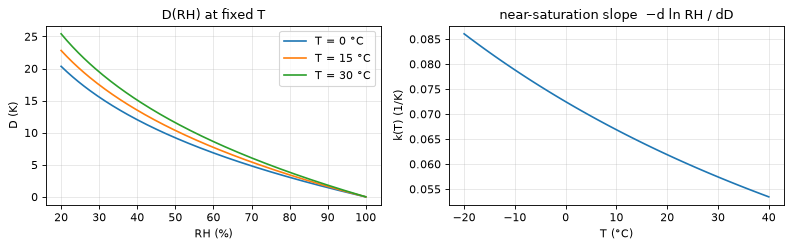

exact identity check: max |lhs - rhs| = 1.3e-15
k(T) spans 0.0534..0.0860 1/K over -20..40 °C (±23 %)


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
rh = np.linspace(20, 100, 161)
for tt in (0, 15, 30):
    ax[0].plot(rh, thermo.depression(tt, rh), label=f'T = {tt} °C')
ax[0].set(xlabel='RH (%)', ylabel='D (K)', title='D(RH) at fixed T'); ax[0].legend()
tt = np.linspace(-20, 40, 61)
k = thermo.B * thermo.C / (thermo.C + tt) ** 2
ax[1].plot(tt, k); ax[1].set(xlabel='T (°C)', ylabel='k(T) (1/K)', title='near-saturation slope  −d ln RH / dD')
plt.tight_layout(); plt.show()
D = thermo.depression(T, RH)
print(f'exact identity check: max |lhs - rhs| = {np.abs(np.log(RH / 100) + thermo.B * thermo.C * D / ((thermo.C + T) * (thermo.C + T - D))).max():.1e}')
print(f'k(T) spans {k.min():.4f}..{k.max():.4f} 1/K over -20..40 °C (±{100 * (k.max() - k.min()) / (k.max() + k.min()):.0f} %)')

## 4 · Fixed vapour, changing temperature: the thermometer pathway

Hold the dew point at 12 °C and let air temperature follow a diurnal cycle. Neither the water content nor anything optically "moist" changes, yet RH swings by tens of percent and `D` by more than 10 K. A camera that only recognises the time of day or the warmth of the scene would predict this RH swing without observing moisture. The same identity governs a radiatively heated probe: if the sensing element warms by δ while vapour pressure is unchanged, the probe's dew point stays correct and its `D` reads high by exactly δ.

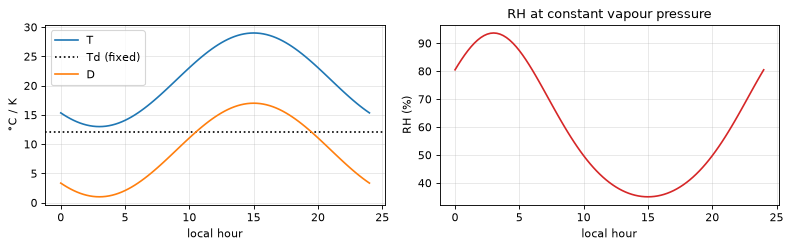

RH range 35.0..93.7 %, D range 1.0..17.0 K
probe heated by 1.5 K -> D error: [1.5 1.5 1.5 1.5 1.5]


In [6]:
h = np.linspace(0, 24, 97)
temp = 21 + 8 * np.cos(2 * np.pi * (h - 15) / 24)
rh_fix = thermo.rh_from_dewpoint(temp, 12.0)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(h, temp, label='T'); ax[0].axhline(12, c='k', ls=':', label='Td (fixed)'); ax[0].plot(h, temp - 12, label='D'); ax[0].set(xlabel='local hour', ylabel='°C / K'); ax[0].legend()
ax[1].plot(h, rh_fix, c='C3'); ax[1].set(xlabel='local hour', ylabel='RH (%)', title='RH at constant vapour pressure')
plt.tight_layout(); plt.show()
print(f'RH range {rh_fix.min():.1f}..{rh_fix.max():.1f} %, D range {(temp - 12).min():.1f}..{(temp - 12).max():.1f} K')
delta = 1.5  # radiative heating of a probe, K
print('probe heated by 1.5 K -> D error:', np.round(thermo.depression(temp[::24] + delta, thermo.rh_from_dewpoint(temp[::24] + delta, 12.0)) - (temp[::24] - 12), 10))

## 5 · Instrument error floor and a censoring rule fixed before seeing labels

First-order propagation: `σ_D² = (∂D/∂T)² σ_T² + (∂D/∂RH)² σ_RH²`. At fixed RH, `∂D/∂T ≈ 0.08`, so temperature error barely matters; RH error dominates everywhere. Near saturation `D ≈ (100 − RH)/(100k)` and `σ_D ≈ σ_RH/(k·RH)`, which gives a temperature-free signal-to-noise ratio

$$\frac{D}{\sigma_D} \approx \frac{(100-RH)\,RH}{100\,\sigma_{RH}} \approx \frac{100-RH}{\sigma_{RH}}.$$

A label with `D/σ_D < 1` cannot be distinguished from saturation, so the censoring limit is set from the instrument specification alone: `RH_c = 100 − σ_RH` (k = 1), or `100 − 2σ_RH` for a conservative rule. This is the rule `thermo.label_d` implements; it never looks at the label distribution.

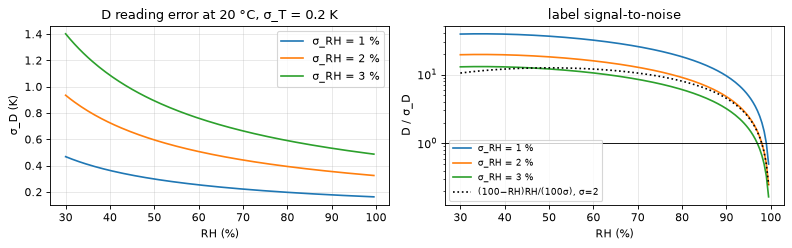

,dD_dT,dD_dRH_K_per_pct,D_k,"sd_D_k(2%,0.2K)"
rh_pct,,,,
30,0.1330,-0.4671,18.1181,0.9345
50,0.0800,-0.2974,10.7448,0.5950
70,0.0424,-0.2211,5.6408,0.4423
90,0.0128,-0.1773,1.6918,0.3545
95,0.0063,-0.1691,0.8264,0.3381
98,0.0025,-0.1645,0.3261,0.3290


In [7]:
rh = np.linspace(30, 99.5, 140)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for s in (1, 2, 3):
    sd = thermo.d_sd(20.0, rh, sd_t=0.2, sd_rh=s)
    ax[0].plot(rh, sd, label=f'σ_RH = {s} %'); ax[1].plot(rh, thermo.depression(20.0, rh) / sd, label=f'σ_RH = {s} %')
ax[1].plot(rh, (100 - rh) * rh / 100 / 2, 'k:', label='(100−RH)RH/(100σ), σ=2')
ax[0].set(xlabel='RH (%)', ylabel='σ_D (K)', title='D reading error at 20 °C, σ_T = 0.2 K'); ax[0].legend()
ax[1].set(xlabel='RH (%)', ylabel='D / σ_D', yscale='log', title='label signal-to-noise'); ax[1].axhline(1, c='k', lw=.8); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

gt, grh = thermo.d_sensitivity(20.0, np.array([30, 50, 70, 90, 95, 98]))
pd.DataFrame({'dD_dT': gt, 'dD_dRH_K_per_pct': grh, 'D_k': thermo.depression(20.0, np.array([30, 50, 70, 90, 95, 98])),
              'sd_D_k(2%,0.2K)': thermo.d_sd(20.0, np.array([30, 50, 70, 90, 95, 98]), .2, 2)}, index=pd.Index([30, 50, 70, 90, 95, 98], name='rh_pct'))

In [8]:
for s in (1, 2, 3):
    for tt in (0, 20, 35):
        r = np.linspace(80, 99.99, 20000)
        snr = thermo.depression(tt, r) / thermo.d_sd(tt, r, .2, s)
        print(f'σ_RH={s}%  T={tt:>2} °C: D/σ_D = 1 at RH = {r[np.argmin(np.abs(snr - 1))]:.2f} %   (rule 100-σ = {100 - s} %)')

σ_RH=1%  T= 0 °C: D/σ_D = 1 at RH = 99.00 %   (rule 100-σ = 99 %)
σ_RH=1%  T=20 °C: D/σ_D = 1 at RH = 99.00 %   (rule 100-σ = 99 %)
σ_RH=1%  T=35 °C: D/σ_D = 1 at RH = 99.00 %   (rule 100-σ = 99 %)
σ_RH=2%  T= 0 °C: D/σ_D = 1 at RH = 97.98 %   (rule 100-σ = 98 %)
σ_RH=2%  T=20 °C: D/σ_D = 1 at RH = 97.98 %   (rule 100-σ = 98 %)
σ_RH=2%  T=35 °C: D/σ_D = 1 at RH = 97.98 %   (rule 100-σ = 98 %)
σ_RH=3%  T= 0 °C: D/σ_D = 1 at RH = 96.96 %   (rule 100-σ = 97 %)
σ_RH=3%  T=20 °C: D/σ_D = 1 at RH = 96.96 %   (rule 100-σ = 97 %)
σ_RH=3%  T=35 °C: D/σ_D = 1 at RH = 96.96 %   (rule 100-σ = 97 %)


The exact crossing sits within 0.05 %RH of `100 − σ_RH` at every temperature tested, so the censoring limit is effectively temperature-independent. With a ±2 %RH probe, rows above ~98 %RH carry an upper bound on `D`, not a value, and must be scored with `P(D ≤ d_c)` (`scoring.gauss_ls(..., censored=...)`). Fog/dew regimes, which are the most visually distinctive, are exactly where labels are weakest; any claim about them must use censored likelihoods.

## 6 · The synthetic world used to validate estimators

Conditional on local hour, every node is linear in its parents plus Gaussian noise; a share of each noise variance is constant within a day and the remainder is AR(1) within the day, so rows are dependent like real 15-min samples. Because the marginal covariance is known, any `I(D; V | hour, ·)` is exact (`synthetic.cmi`).

| node | meaning | structure |
|---|---|---|
| `temp_cond_c` | air temperature | diurnal mean 20 ± 5 °C, anomaly SD 3 K, 70 % day-level |
| `dres` | moisture state not explained by hour and T | SD 2 K, 50 % day-level |
| `d_ref_k` | label `D` | diurnal mean + 0.4·T + `dres` |
| `vis_moist` | visual cue of the moisture residual | γ·`dres` + noise |
| `vis_temp` | visual thermometer (scene warmth, shimmer) | T + noise (SD 1.5 K) |
| `vis_sun` | sun-elevation cue | deterministic in hour + tiny noise |

`γ = 0.162` makes `E2 = I(D; vis_moist | hour, T) = 0.05` nats, the illustrative effect size from earlier planning.

In [9]:
cyc = lambda a, b: (lambda h: a + b * np.cos(2 * np.pi * (h - 15) / 24))
world = {'temp_cond_c': Node(sd=3, mean=cyc(20, 5), day=.7, ar=.95),
         'dres': Node(sd=2, day=.5, ar=.9),
         'd_ref_k': Node({'temp_cond_c': .4, 'dres': 1}, mean=cyc(-1, 2)),
         'vis_moist': Node({'dres': .162}, 1.0, day=.3, ar=.5),
         'vis_temp': Node({'temp_cond_c': 1}, 1.5),
         'vis_sun': Node(sd=.05, mean=lambda h: np.sin(np.pi * (h - 6) / 12))}
info = pd.DataFrame({v: {'E1 = I(D;V|hour)': synthetic.cmi(world, 'd_ref_k', v), 'E2 = I(D;V|hour,T)': synthetic.cmi(world, 'd_ref_k', v, 'temp_cond_c')}
                     for v in ['vis_moist', 'vis_temp', 'vis_sun']}).T
info.loc['all three'] = [synthetic.cmi(world, 'd_ref_k', ['vis_moist', 'vis_temp', 'vis_sun']), synthetic.cmi(world, 'd_ref_k', ['vis_moist', 'vis_temp', 'vis_sun'], 'temp_cond_c')]
info

,E1 = I(D;V|hour),"E2 = I(D;V|hour,T)"
vis_moist,0.0362,0.0499
vis_temp,0.1190,0.0000
vis_sun,0.0000,0.0000
all three,0.1654,0.0499


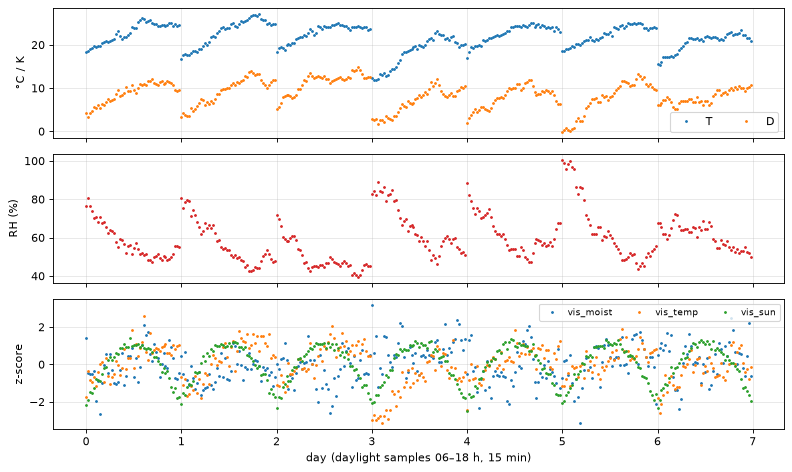

D < 0 (supersaturated, unphysical) in 0.45% of rows; lag-1 autocorr of dres 0.93, between-day share of dres variance 0.69


In [10]:
df = synthetic.simulate(world, n_days=7, seed=1)
df['rh'] = thermo.rh_from_d(df.temp_cond_c, df.d_ref_k)
x = df.day + (df.hour - 6) / 12
fig, ax = plt.subplots(3, 1, figsize=(10, 6), sharex=True)
ax[0].plot(x, df.temp_cond_c, '.', ms=3, label='T'); ax[0].plot(x, df.d_ref_k, '.', ms=3, label='D'); ax[0].legend(ncol=2); ax[0].set_ylabel('°C / K')
ax[1].plot(x, df.rh, '.', ms=3, c='C3'); ax[1].set_ylabel('RH (%)')
for v in ['vis_moist', 'vis_temp', 'vis_sun']: ax[2].plot(x, (df[v] - df[v].mean()) / df[v].std(), '.', ms=3, label=v)
ax[2].legend(ncol=3, fontsize=8); ax[2].set(ylabel='z-score', xlabel='day (daylight samples 06–18 h, 15 min)')
plt.tight_layout(); plt.show()
big = synthetic.simulate(world, n_days=500, seed=2)
print(f'D < 0 (supersaturated, unphysical) in {(big.d_ref_k < 0).mean():.2%} of rows; lag-1 autocorr of dres {big.dres.autocorr():.2f}, '
      f'between-day share of dres variance {big.groupby("day").dres.mean().var() / big.dres.var():.2f}')

**Reading the table.** `vis_temp` carries 0.119 nats about `D` when only hour is known (E1) and exactly zero once T is known (E2): a pure visual thermometer. `vis_sun` carries nothing beyond hour. `vis_moist` is *more* informative under E2 (0.050) than under E1 (0.036) although its signal is independent of T: conditioning on T removes the 1.44 K² of T-driven variance from `D`, so the same visual signal explains a larger share of what remains. Hence `E1 − E2` has no fixed sign; it is an interaction information, and "E1 > E2" cannot be used as a test for thermometry without the full table. These behaviours are the positive, shortcut and null controls for notebook 01.

The Gaussian world is a device for exact information values, not a climate model: it allows a small share of `D < 0` rows (reported above, not clipped) and has no censoring, skew, or regime-dependent variance. Those departures are where real estimators can fail; notebook 01 adds the variance-regime case explicitly.